До начала анализа данных сформулируем бизнес задачу и сформулируем гипотезы

**Бизнес-задача:** оценить влияние двух вариантов email-рассылки на покупательскую активность клиентов и определить наиболее эффективную стратегию с приоритетом увеличения конверсии.


**Основная метрика:** конверсия в покупку за 14 дней.

**Дополнительная метрика:** средняя выручка на клиента за 14 дней.

### Статистические гипотезы

Обозначения:
- $p_C$ — конверсия контрольной группы;
- $p_M$ — конверсия группы с мужской рассылкой;
- $p_W$ — конверсия группы с женской рассылкой.

**1. Мужская рассылка против контроля**

- $H_0: p_M = p_C$
- $H_1: p_M \neq p_C$

**2. Женская рассылка против контроля**

- $H_0: p_W = p_C$
- $H_1: p_W \neq p_C$

**3. Мужская рассылка против женской**

- $H_0: p_M = p_W$
- $H_1: p_M \neq p_W$



## 1. Загрузка и первичная проверка данных

In [78]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chisquare
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep
from scipy.stats import ttest_ind
from statsmodels.stats.weightstats import CompareMeans, DescrStatsW

In [10]:
df = pd.read_csv("Data.csv")

In [11]:
df.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
 8   segment          64000 non-null  object 
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 5.9+ MB


In [13]:
df.describe()

,recency,history,mens,womens,newbie,visit,conversion,spend
count,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000
mean,5.763734,242.085656,0.551031,0.549719,0.502250,0.146781,0.009031,1.050908
std,3.507592,256.158608,0.497393,0.497526,0.499999,0.353890,0.094604,15.036448
min,1.000000,29.990000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,64.660000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,6.000000,158.110000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
75%,9.000000,325.657500,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
max,12.000000,3345.930000,1.000000,1.000000,1.000000,1.000000,1.000000,499.000000


In [14]:
df.describe(include="object")

,history_segment,zip_code,channel,segment
count,64000,64000,64000,64000
unique,7,3,3,3
top,1) $0 - $100,Surburban,Web,Womens E-Mail
freq,22970,28776,28217,21387


### Выводы по первичной проверке данных

В датасете содержится 64 000 наблюдений и 12 признаков. Пропущенные значения отсутствуют, типы данных соответствуют содержанию столбцов.

Распределение пользователей между тремя экспериментальными группами близко к равномерному — примерно по 21,3 тыс. человек в каждой группе.

На этапе первичной проверки явных проблем с качеством данных не обнаружено.

In [15]:
df["segment"].value_counts()

,count
segment,
Womens E-Mail,21387
Mens E-Mail,21307
No E-Mail,21306



### Проверка равномерности распределения пользователей (SRM)

Для проверки соответствия фактического распределения пользователей ожидаемому соотношению 1:1:1 используем критерий согласия хи-квадрат Пирсона.

**Нулевая гипотеза ($H_0$):** пользователи распределены между тремя экспериментальными группами равномерно.

$$
H_0: p_C = p_M = p_W = \frac{1}{3}
$$

**Альтернативная гипотеза ($H_1$):** распределение пользователей отличается от равномерного, то есть хотя бы одна из вероятностей попадания в группу не равна $1/3$.

$$
H_1: \exists\, i \in \{C,M,W\}: p_i \neq \frac{1}{3}
$$

Уровень значимости: $\alpha = 0.05$.


In [23]:
obs = df["segment"].value_counts()
res = chisquare(f_obs=obs)

print(f"Chi-square: {res.statistic:.4f}")
print(f"P-value: {res.pvalue:.4f}")

if res.pvalue < 0.05:
    print("Отвергаем H0: обнаружено значимое отклонение от равномерного распределения.")
else:
    print("Не отвергаем H0: значимых отклонений от равномерного распределения не обнаружено.")

Chi-square: 0.2025
P-value: 0.9037
Не отвергаем H0: значимых отклонений от равномерного распределения не обнаружено.


In [24]:
balance = df.groupby("segment").agg(
    n=("recency", "size"),
    recency_mean=("recency", "mean"),
    recency_median=("recency", "median"),
    history_mean=("history", "mean"),
    history_median=("history", "median"),
    newbie_share=("newbie", "mean")
)

balance["newbie_share"] *= 100

display(balance.round(2))

,n,recency_mean,recency_median,history_mean,history_median,newbie_share
segment,,,,,,
Mens E-Mail,21307,5.77,6.0,242.84,157.22,50.15
No E-Mail,21306,5.75,5.0,240.88,156.66,50.20
Womens E-Mail,21387,5.77,6.0,242.54,160.09,50.32


In [25]:
channel_dist = pd.crosstab(
    df["segment"],
    df["channel"],
    normalize="index"
) * 100

display(channel_dist.round(2))

channel,Multichannel,Phone,Web
segment,,,
Mens E-Mail,12.09,43.37,44.54
No E-Mail,12.23,43.78,43.99
Womens E-Mail,12.06,44.20,43.74


### Вывод по проверке экспериментальных групп

Проверка SRM с помощью критерия согласия хи-квадрат Пирсона не выявила статистически значимых отклонений от ожидаемого распределения 1:1:1 (χ² = 0,2025; p-value = 0,9037).

Сравнение характеристик клиентов до эксперимента также не выявило заметных различий между группами. Средние исторические расходы, давность последней покупки, доля новых клиентов и распределение по каналам покупок близки.

Таким образом, на данном этапе не обнаружено признаков существенного дисбаланса экспериментальных групп.

In [47]:
analisys = df.groupby("segment").agg(
    number_users=("conversion", "size"),
    number_buyers=("conversion", "sum"),
    spend=("spend", "sum"),
    RPU=("spend", "mean"),
    conversion=("conversion", "mean"),

)

analisys["conversion"] = (analisys["conversion"] * 100).round(2)

analisys

,number_users,number_buyers,spend,RPU,conversion
segment,,,,,
Mens E-Mail,21307,267,30311.69,1.422617,1.25
No E-Mail,21306,122,13908.33,0.652789,0.57
Womens E-Mail,21387,189,23038.11,1.077202,0.88


В обеих экспериментальных группах наблюдается более высокая конверсия по сравнению с контролем. Наибольшая конверсия зафиксирована в группе Men's Email. Статистическая значимость различий будет оценена на следующем этапе.

In [48]:
pairs = [
    ("Mens E-Mail", "No E-Mail"),
    ("Womens E-Mail", "No E-Mail"),
    ("Mens E-Mail", "Womens E-Mail")
]

results = []

for group_a, group_b in pairs:
    p_a = analisys.loc[group_a, "number_buyers"] / analisys.loc[group_a, "number_users"]
    p_b = analisys.loc[group_b, "number_buyers"] / analisys.loc[group_b, "number_users"]

    results.append({
        "comparison": f"{group_a} vs {group_b}",
        "absolute_diff_pp": round((p_a - p_b) * 100, 3),
        "relative_diff_pct": round((p_a / p_b - 1) * 100, 2)
    })

effects = pd.DataFrame(results)
display(effects)

,comparison,absolute_diff_pp,relative_diff_pct
0,Mens E-Mail vs No E-Mail,0.681,118.84
1,Womens E-Mail vs No E-Mail,0.311,54.33
2,Mens E-Mail vs Womens E-Mail,0.369,41.80


Проверяем:

$$
H_0:p_M=p_C
$$

$$
H_1:p_M\neq p_C
$$

In [53]:
pairs = [
    ("Mens E-Mail", "No E-Mail"),
    ("Womens E-Mail", "No E-Mail"),
    ("Mens E-Mail", "Womens E-Mail")
]

test_results = []

for group_a, group_b in pairs:
    count = [
        analisys.loc[group_a, "number_buyers"],
        analisys.loc[group_b, "number_buyers"]
    ]

    nobs = [
        analisys.loc[group_a, "number_users"],
        analisys.loc[group_b, "number_users"]
    ]

    z_stat, p_value = proportions_ztest(
        count=count,
        nobs=nobs,
        alternative="two-sided"
    )

    test_results.append({
        "comparison": f"{group_a} vs {group_b}",
        "z_stat": z_stat,
        "p_value": p_value
    })

test_results = pd.DataFrame(test_results)

display(test_results)

,comparison,z_stat,p_value
0,Mens E-Mail vs No E-Mail,7.385114,1.523224e-13
1,Womens E-Mail vs No E-Mail,3.779561,1.571051e-04
2,Mens E-Mail vs Womens E-Mail,3.712584,2.051538e-04


Наибольшая конверсия наблюдается у мужской рассылки — 1,25%, что на 0,68 п.п. выше контрольной группы. Женская рассылка также показывает конверсию выше контроля — 0,88% против 0,57%.

Z-тест подтвердил статистически значимое различие между мужской рассылкой и контролем (p-value ≈ 1,52 × 10⁻¹³). Пока это предварительный результат: окончательные выводы сделаем после проверки остальных сравнений и применения поправки Холма.

In [64]:
reject, pvals_corrected, _, _ = multipletests(
    test_results["p_value"],
    alpha=0.05,
    method="holm"
)

test_results["p_value_holm"] = pvals_corrected
test_results["significant"] = reject

display(
    test_results.style.format({
        "z_stat": "{:.4f}",
        "p_value": "{:.3e}",
        "p_value_holm": "{:.3e}"
    })
)

,comparison,z_stat,p_value,p_value_holm,significant
0,Mens E-Mail vs No E-Mail,7.3851,1.523e-13,4.570e-13,True
1,Womens E-Mail vs No E-Mail,3.7796,1.571e-04,3.142e-04,True
2,Mens E-Mail vs Womens E-Mail,3.7126,2.052e-04,3.142e-04,True


После применения поправки Холма все три различия конверсий остались статистически значимыми (скорректированные p-value < 0,001).

Обе email-рассылки показывают более высокую конверсию по сравнению с контрольной группой. При этом мужская рассылка значительно эффективнее женской: 1,25% против 0,88%.

Таким образом, по основной метрике лучшей стратегией является мужская рассылка. Для окончательных рекомендаций необходимо оценить доверительные интервалы и дополнительную метрику — среднюю выручку на клиента.

,comparison,effect_pp,ci_low,ci_high
0,Mens E-Mail vs No E-Mail,0.681,0.462,0.906
1,Womens E-Mail vs No E-Mail,0.311,0.114,0.512
2,Mens E-Mail vs Womens E-Mail,0.369,0.131,0.611


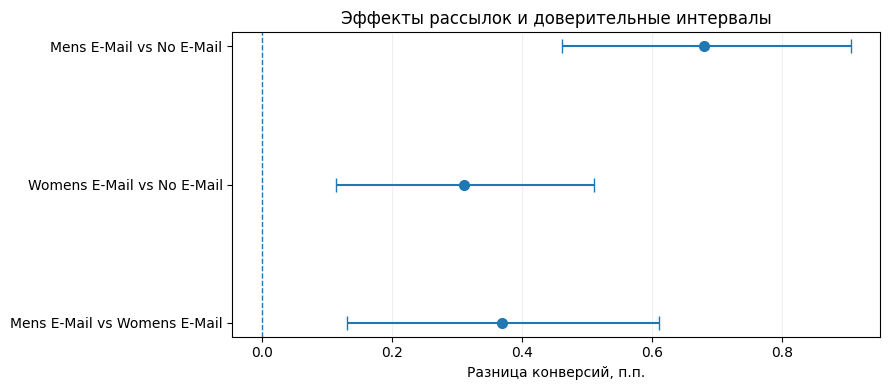

In [81]:
results = []


for group_a, group_b in pairs:
    x1, n1 = analisys.loc[group_a, ["number_buyers", "number_users"]]
    x2, n2 = analisys.loc[group_b, ["number_buyers", "number_users"]]

    low, high = confint_proportions_2indep(
        x1, n1, x2, n2,
        compare="diff",
        method="newcomb",
        alpha=0.05 / len(pairs) #Используем поправку Бонферони
    )

    results.append({
        "comparison": f"{group_a} vs {group_b}",
        "effect_pp": 100 * (x1 / n1 - x2 / n2),
        "ci_low": 100 * low,
        "ci_high": 100 * high
    })

ci_results = pd.DataFrame(results)
display(ci_results.round(3))

# Визуализация
fig, ax = plt.subplots(figsize=(9, 4))

ax.errorbar(
    ci_results["effect_pp"],
    ci_results["comparison"],
    xerr=[
        ci_results["effect_pp"] - ci_results["ci_low"],
        ci_results["ci_high"] - ci_results["effect_pp"]
    ],
    fmt="o",
    capsize=5,
    markersize=7
)

ax.axvline(0, linestyle="--", linewidth=1)
ax.set_xlabel("Разница конверсий, п.п.")
ax.set_title("Эффекты рассылок и доверительные интервалы")
ax.grid(axis="x", alpha=0.2)
ax.invert_yaxis()

plt.tight_layout()
fig.savefig("conversion_ci.png", dpi=200, bbox_inches="tight")
plt.show()

Все три доверительных интервала находятся выше нуля, что подтверждает статистически значимые различия между группами с учётом множественных сравнений.

Наибольший эффект наблюдается у мужской рассылки относительно контроля: прирост конверсии составляет 0,68 п.п. (доверительный интервал: 0,46–0,91 п.п.).

Мужская рассылка также превосходит женскую на 0,37 п.п. (0,13–0,61 п.п.). Таким образом, по основной метрике мужская рассылка показала лучший результат.

## Исследование распределения расходов


In [67]:
buyers = df[df["spend"] > 0]

spend_stats = buyers.groupby("segment")["spend"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    p95=lambda x: x.quantile(0.95),
    p99=lambda x: x.quantile(0.99),
    max="max"
)

display(spend_stats.round(2))

,count,mean,median,std,p95,p99,max
segment,,,,,,,
Mens E-Mail,267,113.53,66.98,111.68,373.93,499.00,499.0
No E-Mail,122,114.00,88.36,103.03,362.98,487.64,499.0
Womens E-Mail,189,121.89,94.71,105.77,349.10,499.00,499.0


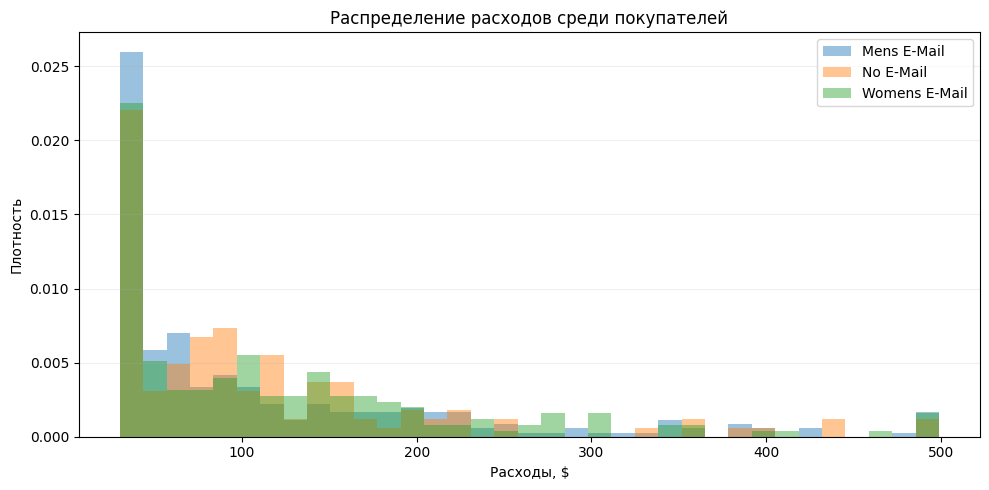

In [82]:
fig, ax = plt.subplots(figsize=(10, 5))

limit = buyers["spend"].quantile(0.99)

for group, data in buyers.groupby("segment"):
    ax.hist(
        data["spend"].clip(upper=limit),
        bins=35,
        alpha=0.45,
        density=True,
        label=group
    )

ax.set(
    title="Распределение расходов среди покупателей",
    xlabel="Расходы, $",
    ylabel="Плотность"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
fig.savefig("spend distribution.png", dpi=200, bbox_inches="tight")
plt.show()

In [76]:
results = []

for group_a, group_b in pairs:
    a = df.loc[df["segment"] == group_a, "spend"]
    b = df.loc[df["segment"] == group_b, "spend"]

    t_stat, p_value = ttest_ind(a, b, equal_var=False)

    results.append({
        "comparison": f"{group_a} vs {group_b}",
        "rpu_diff": a.mean() - b.mean(),
        "t_stat": t_stat,
        "p_value": p_value
    })

rpu_tests = pd.DataFrame(results)

rpu_tests["p_value_holm"] = multipletests(
    rpu_tests["p_value"],
    alpha=0.05,
    method="holm"
)[1]

rpu_tests["significant"] = rpu_tests["p_value_holm"] < 0.05

display(
    rpu_tests.style.format({
        "rpu_diff": "{:+.3f}",
        "t_stat": "{:.4f}",
        "p_value": "{:.3e}",
        "p_value_holm": "{:.3e}"
    })
)

,comparison,rpu_diff,t_stat,p_value,p_value_holm,significant
0,Mens E-Mail vs No E-Mail,+0.770,5.3001,1.164e-07,3.491e-07,True
1,Womens E-Mail vs No E-Mail,+0.424,3.2564,1.129e-03,2.259e-03,True
2,Mens E-Mail vs Womens E-Mail,+0.345,2.1640,3.047e-02,3.047e-02,True


### Вывод по анализу выручки

Средняя выручка на клиента (RPU) оказалась наибольшей в группе Men's Email — 1,42 USD против 1,08 USD у Women's Email и 0,65 USD в контрольной группе.

Распределение расходов сильно асимметрично: большинство клиентов ничего не купили, а средние расходы среди покупателей во всех трёх группах относительно близки. Таким образом, различия в RPU в основном связаны с разницей в конверсии.

Для сравнения средней выручки использовался t-критерий Уэлча. После поправки Холма все три различия остались статистически значимыми (p-value < 0,05).

Мужская рассылка показала лучший результат и по дополнительной метрике: средняя выручка на клиента выше контрольной на 0,77 USD, а женской рассылки — на 0,35 USD.</

,comparison,rpu_diff,ci_low,ci_high
0,Mens E-Mail vs No E-Mail,0.770,0.422,1.118
1,Womens E-Mail vs No E-Mail,0.424,0.112,0.736
2,Mens E-Mail vs Womens E-Mail,0.345,-0.037,0.728


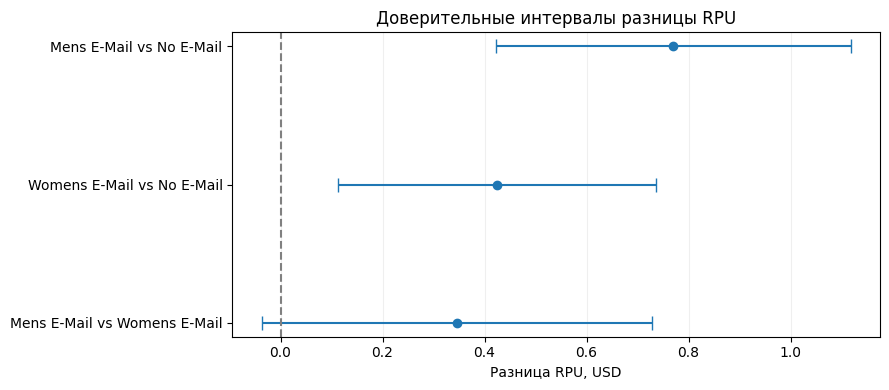

In [83]:
results = []

for group_a, group_b in pairs:
    a = df.loc[df["segment"] == group_a, "spend"]
    b = df.loc[df["segment"] == group_b, "spend"]

    test = ttest_ind(a, b, equal_var=False)
    ci = test.confidence_interval(confidence_level=1 - 0.05 / 3)

    results.append({
        "comparison": f"{group_a} vs {group_b}",
        "rpu_diff": a.mean() - b.mean(),
        "ci_low": ci.low,
        "ci_high": ci.high
    })

rpu_ci = pd.DataFrame(results)
display(rpu_ci.round(3))

fig, ax = plt.subplots(figsize=(9, 4))

ax.errorbar(
    rpu_ci["rpu_diff"],
    rpu_ci["comparison"],
    xerr=[
        rpu_ci["rpu_diff"] - rpu_ci["ci_low"],
        rpu_ci["ci_high"] - rpu_ci["rpu_diff"]
    ],
    fmt="o",
    capsize=5
)

ax.axvline(0, color="gray", linestyle="--")
ax.set_xlabel("Разница RPU, USD")
ax.set_title("Доверительные интервалы разницы RPU")
ax.grid(axis="x", alpha=0.2)
ax.invert_yaxis()

plt.tight_layout()
fig.savefig("RPU_ci.png", dpi=200, bbox_inches="tight")
plt.show()

### Итоговые выводы

Лучший результат показала мужская рассылка: конверсия составила 1,25% против 0,88% у женской и 0,57% в контрольной группе. Все различия статистически значимы после поправки Холма.

По RPU также лидирует мужская рассылка — 1,42 USD на клиента против 1,08 и 0,65 USD соответственно. Обе рассылки значимо увеличили RPU относительно контроля. Разница между мужской и женской рассылками значима по тесту Холма, но доверительный интервал Бонферрони включает ноль.

**Рекомендация:** выбрать мужскую рассылку как наиболее эффективную по основной метрике. При этом для оценки прибыльности необходимо учитывать затраты на рассылки.